In [1]:
%pip install catboost

In [2]:
import catboost
import pandas as pd
import sklearn
import numpy as np
from pathlib import Path
from sklearn.model_selection import PredefinedSplit

RANDOM_STATE = 42
TARGET = "vae_positive_local"
INCLUDE_DEMOGRAPHICS = False

# Feature-engineered data (notebooks/modeling/Feature_Engineering.ipynb)
DATA_DIR = Path("../../../data/processed/model")
dictionary = pd.read_csv(DATA_DIR / "feature_dictionary.csv")
CAT_FEATURES = dictionary.loc[dictionary["type"] == "categorical", "feature"].tolist()

df = pd.read_csv(DATA_DIR / "model_features.csv", low_memory=False, dtype={c: str for c in CAT_FEATURES})

labeled = df[df["split"] == "train"].copy()     # training rows; the shared test split is used once at the end
holdout = df[df["split"] == "test"].copy()   # held-out test set (named "holdout" so the CV loops below don't overwrite it)
y = labeled[TARGET].astype(int)
y_holdout = holdout[TARGET].astype(int)
groups = labeled["unitid"]

cv = PredefinedSplit(labeled["cv_fold"])        # shared 5 folds, grouped by school

print("DATASET OVERVIEW")
print("=" * 50)
print(f"Total programs: {len(df):,}")
print(f"Training programs: {len(labeled):,} | held-out test: {len(holdout):,}")
print(f"Training institutions: {groups.nunique():,}")
print(f"Unlabeled (scored only): {(df['split'] == 'score_only').sum():,}")

print("\nTARGET DISTRIBUTION (training)")
print("=" * 50)
print(y.value_counts().sort_index())

print("\nTARGET DISTRIBUTION (%)")
print("=" * 50)
print(y.value_counts(normalize=True).sort_index().mul(100).round(2))

DATASET OVERVIEW
Total programs: 26,678
Training programs: 5,619 | held-out test: 1,405
Training institutions: 1,642
Unlabeled (scored only): 19,654

TARGET DISTRIBUTION (training)
vae_positive_local
0    1217
1    4402
Name: count, dtype: int64

TARGET DISTRIBUTION (%)
vae_positive_local
0    21.66
1    78.34
Name: proportion, dtype: float64


In [3]:
# Column drops, leakage removal and categorical clean-up were done in feature engineering;
# the feature list comes from the feature dictionary.
LEAKAGE = [
    "earn_mdn_1yr", "earn_mdn_5yr", "earn_mdn_hi_1yr", "earn_count_wne_1yr", "earn_count_wne_5yr",
    "y1_earnings_program", "y5_earnings_program", "y1_earnings_program_status", "y5_earnings_program_status",
    "earnings_1yr", "earnings_1yr_local_adj", "value_added_earnings_local", "earnings_vs_local_field",
    "vae_positive_local", "passes_vae_local", "etpl_prog_earnings"
]
DEMOGRAPHICS = ["ugds_white", "ugds_black", "ugds_hisp", "ugds_asian", "ugds_aian", "ugds_nhpi", "ugds_2mor"]

FEATURES = dictionary["feature"].tolist()
if INCLUDE_DEMOGRAPHICS:
    FEATURES += DEMOGRAPHICS
NUMERIC_FEATURES = [c for c in FEATURES if c not in CAT_FEATURES]


def prepare(frame):
    """CatBoost reads categoricals as strings; blanks become their own category."""
    X = frame[FEATURES].copy()
    X[CAT_FEATURES] = X[CAT_FEATURES].fillna("missing").astype(str)
    return X


X = prepare(labeled)
X_holdout = prepare(holdout)

print("FEATURE SELECTION RESULTS")
print("=" * 50)
print(f"Features: {len(FEATURES)} ({len(NUMERIC_FEATURES)} numeric, {len(CAT_FEATURES)} categorical)")
print(f"Categorical (native CatBoost handling): {CAT_FEATURES}")
print(f"Training shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Institutions: {groups.nunique():,}")
print(f"Demographics included: {INCLUDE_DEMOGRAPHICS}")
print(f"Missing numeric cells: {X[NUMERIC_FEATURES].isna().sum().sum():,}")

print("\nTARGET LEAKAGE CHECK")
print(set(FEATURES) & set(LEAKAGE))

FEATURE SELECTION RESULTS
Features: 121 (109 numeric, 12 categorical)
Categorical (native CatBoost handling): ['bea_region', 'cipcode', 'cip_series', 'y1_earnings_natl_benchmark_level', 'iclevel', 'control', 'highest_offering', 'calendar_system', 'price_reporting', 'locale', 'locale_group', 'preddeg']
Training shape: (5619, 121)
Target shape: (5619,)
Institutions: 1,642
Demographics included: False
Missing numeric cells: 96,701

TARGET LEAKAGE CHECK
set()


In [4]:
from catboost import CatBoostClassifier

BALANCE = True

n_negative = (y == 0).sum()
n_positive = (y == 1).sum()

scale_pos_weight = (n_negative / n_positive if BALANCE else 1.0)

catboost_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    scale_pos_weight=scale_pos_weight,
    random_seed=RANDOM_STATE,
    verbose=False,
    thread_count=-1,
    cat_features=CAT_FEATURES,
    allow_writing_files=False
)

print("CATBOOST CONFIGURATION")
print("=" * 50)
print(f"Class balancing enabled: {BALANCE}")
print(f"Negative class count: {n_negative:,}")
print(f"Positive class count: {n_positive:,}")
print(f"Positive class weight: {scale_pos_weight:.4f}")
print(f"Cross-validation: {cv.get_n_splits()} folds")
print(f"Grouping variable: unitid (shared cv_fold column)")
print(f"Training features: {X.shape[1]}")
print(f"Training observations: {X.shape[0]:,}")

print("\nCROSS-VALIDATION FOLD CHECK")
print("=" * 50)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    train_schools = set(groups.iloc[train_idx])
    test_schools = set(groups.iloc[test_idx])

    overlap = train_schools & test_schools

    print(
        f"Fold {fold}: "
        f"Train={len(train_idx):,}, "
        f"Test={len(test_idx):,}, "
        f"School overlap={len(overlap)}"
    )

CATBOOST CONFIGURATION
Class balancing enabled: True
Negative class count: 1,217
Positive class count: 4,402
Positive class weight: 0.2765
Cross-validation: 5 folds
Grouping variable: unitid (shared cv_fold column)
Training features: 121
Training observations: 5,619

CROSS-VALIDATION FOLD CHECK
Fold 1: Train=4,498, Test=1,121, School overlap=0
Fold 2: Train=4,489, Test=1,130, School overlap=0
Fold 3: Train=4,497, Test=1,122, School overlap=0
Fold 4: Train=4,497, Test=1,122, School overlap=0
Fold 5: Train=4,495, Test=1,124, School overlap=0


In [5]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

oof_prob = np.zeros(len(y))
oof_pred = np.zeros(len(y), dtype=int)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    print(f"Training Fold {fold}/5...")

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    model = CatBoostClassifier(**catboost_model.get_params())

    model.fit(X_train, y_train)

    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)

    oof_prob[test_idx] = prob
    oof_pred[test_idx] = pred

    results = {
        "Fold": fold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    }

    fold_results.append(results)

    print(
        f"  ROC-AUC: {results['ROC-AUC']:.4f} | "
        f"F1: {results['F1']:.4f}"
    )

fold_df = pd.DataFrame(fold_results)

print("\nCATBOOST — FOLD RESULTS")
print("=" * 65)
print(fold_df.round(4).to_string(index=False))

print("\nCATBOOST — OVERALL OUT-OF-FOLD RESULTS")
print("=" * 65)

overall_metrics = {
    "Accuracy": accuracy_score(y, oof_pred),
    "Precision": precision_score(y, oof_pred),
    "Recall": recall_score(y, oof_pred),
    "F1": f1_score(y, oof_pred),
    "ROC-AUC": roc_auc_score(y, oof_prob)
}

for metric, value in overall_metrics.items():
    print(f"{metric}: {value:.4f}")

Training Fold 1/5...
  ROC-AUC: 0.9546 | F1: 0.9437
Training Fold 2/5...
  ROC-AUC: 0.9522 | F1: 0.9446
Training Fold 3/5...
  ROC-AUC: 0.9359 | F1: 0.9355
Training Fold 4/5...
  ROC-AUC: 0.9430 | F1: 0.9363
Training Fold 5/5...
  ROC-AUC: 0.9657 | F1: 0.9523

CATBOOST — FOLD RESULTS
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC
    1    0.9117     0.9442  0.9431 0.9437   0.9546
    2    0.9133     0.9456  0.9435 0.9446   0.9522
    3    0.8993     0.9382  0.9329 0.9355   0.9359
    4    0.9020     0.9529  0.9204 0.9363   0.9430
    5    0.9262     0.9628  0.9420 0.9523   0.9657

CATBOOST — OVERALL OUT-OF-FOLD RESULTS
Accuracy: 0.9105
Precision: 0.9487
Recall: 0.9364
F1: 0.9425
ROC-AUC: 0.9502


In [6]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform
import time

param_distributions = {
    "iterations": randint(300, 1001),
    "depth": randint(4, 9),
    "learning_rate": uniform(0.02, 0.13),
    "l2_leaf_reg": uniform(2, 10),
    "random_strength": uniform(0, 2)
}

base_model = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    scale_pos_weight=scale_pos_weight,
    random_seed=RANDOM_STATE,
    verbose=False,
    thread_count=2,
    allow_writing_files=False
)

search = RandomizedSearchCV(
    estimator=base_model,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="roc_auc",
    cv=cv,
    refit=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

start_time = time.time()

search.fit(X, y, groups=groups, cat_features=CAT_FEATURES)   # passed at fit time so the search can clone the model

elapsed = time.time() - start_time

print("\nCATBOOST HYPERPARAMETER SEARCH")
print("=" * 55)
print(f"Best CV ROC-AUC: {search.best_score_:.4f}")
print(f"Search time: {elapsed / 60:.2f} minutes")

print("\nBEST PARAMETERS")
for key, value in search.best_params_.items():
    print(f"{key}: {value}")

Fitting 5 folds for each of 30 candidates, totalling 150 fits

CATBOOST HYPERPARAMETER SEARCH
Best CV ROC-AUC: 0.9535
Search time: 17.21 minutes

BEST PARAMETERS
depth: 8
iterations: 789
l2_leaf_reg: 5.584657285442726
learning_rate: 0.03506297773826686
random_strength: 1.726206851751187


In [7]:
from sklearn.metrics import (confusion_matrix)

best_params = search.best_params_

tuned_oof_prob = np.zeros(len(y))
tuned_oof_pred = np.zeros(len(y), dtype=int)

tuned_fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    print(f"Evaluating tuned CatBoost — Fold {fold}/5...")

    model = CatBoostClassifier(
        **best_params,
        loss_function="Logloss",
        eval_metric="AUC",
        scale_pos_weight=scale_pos_weight,
        random_seed=RANDOM_STATE,
        verbose=False,
        thread_count=-1,
        cat_features=CAT_FEATURES,
        allow_writing_files=False
    )

    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    prob = model.predict_proba(X.iloc[test_idx])[:, 1]
    pred = (prob >= 0.5).astype(int)

    tuned_oof_prob[test_idx] = prob
    tuned_oof_pred[test_idx] = pred

    tuned_fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y.iloc[test_idx], pred),
        "Precision": precision_score(y.iloc[test_idx], pred),
        "Recall": recall_score(y.iloc[test_idx], pred),
        "F1": f1_score(y.iloc[test_idx], pred),
        "ROC-AUC": roc_auc_score(y.iloc[test_idx], prob)
    })

tuned_fold_df = pd.DataFrame(tuned_fold_results)

print("\nTUNED CATBOOST — FOLD RESULTS")
print("=" * 65)
print(tuned_fold_df.round(4).to_string(index=False))

print("\nTUNED CATBOOST — OVERALL OUT-OF-FOLD RESULTS")
print("=" * 65)

tuned_metrics = {
    "Accuracy": accuracy_score(y, tuned_oof_pred),
    "Precision": precision_score(y, tuned_oof_pred),
    "Recall": recall_score(y, tuned_oof_pred),
    "F1": f1_score(y, tuned_oof_pred),
    "ROC-AUC": roc_auc_score(y, tuned_oof_prob)
}

for metric, value in tuned_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX")
print("=" * 65)
print(confusion_matrix(y, tuned_oof_pred))

Evaluating tuned CatBoost — Fold 1/5...
Evaluating tuned CatBoost — Fold 2/5...
Evaluating tuned CatBoost — Fold 3/5...
Evaluating tuned CatBoost — Fold 4/5...
Evaluating tuned CatBoost — Fold 5/5...

TUNED CATBOOST — FOLD RESULTS
 Fold  Accuracy  Precision  Recall     F1  ROC-AUC
    1    0.9206     0.9418  0.9579 0.9498   0.9555
    2    0.9212     0.9462  0.9537 0.9499   0.9552
    3    0.9118     0.9392  0.9488 0.9440   0.9428
    4    0.9064     0.9500  0.9295 0.9396   0.9456
    5    0.9333     0.9642  0.9500 0.9571   0.9683

TUNED CATBOOST — OVERALL OUT-OF-FOLD RESULTS
Accuracy: 0.9187
Precision: 0.9482
Recall: 0.9480
F1: 0.9481
ROC-AUC: 0.9533

CONFUSION MATRIX
[[ 989  228]
 [ 229 4173]]


CATBOOST — TOP 20 IMPORTANT FEATURES
                   Feature  Importance
y1_earnings_natl_benchmark    8.507612
      local_earnings_index    3.923671
                   pctpell    3.785608
                bea_region    2.967220
                   cipcode    2.685500
     etpl_bench_completion    2.409561
 has_institution_cip_match    2.165097
                  ret_ftl4    2.113467
           calendar_system    2.098167
    xw_occ_median_wage_max    2.089736
                    locale    2.083571
        expected_vae_field    2.067962
   program_share_of_school    1.968343
      etpl_natl_n_programs    1.954745
     xw_average_importance    1.772690
                   c150_l4    1.725154
                  inexpfte    1.669586
  etpl_bench_employment_q2    1.629279
        xw_occ_median_wage    1.608955
          highest_offering    1.593226


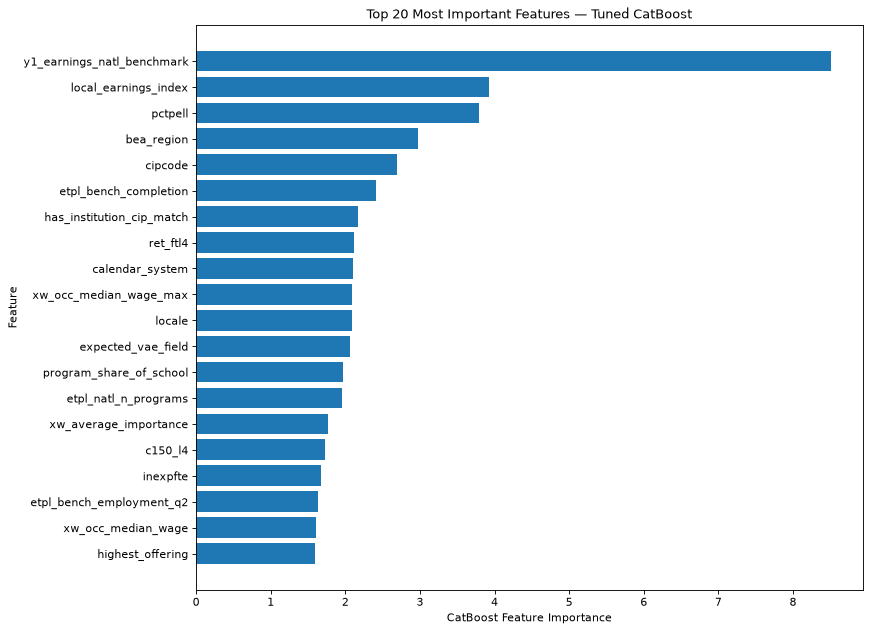

In [8]:
import matplotlib.pyplot as plt

best_model = search.best_estimator_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.get_feature_importance()
})

feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("CATBOOST — TOP 20 IMPORTANT FEATURES")
print("=" * 65)
print(feature_importance.head(20).to_string(index=False))

top_features = feature_importance.head(20)

plt.figure(figsize=(11, 8))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("CatBoost Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Most Important Features — Tuned CatBoost")
plt.tight_layout()
plt.show()

In [9]:
features_to_check = [
    "y1_earnings_natl_benchmark",
    "local_earnings_index",
    "etpl_bench_earnings",
    "etpl_bench_employment_q2"
]

print("FEATURE LEAKAGE REVIEW")
print("=" * 70)

for feature in features_to_check:
    if feature not in X.columns:
        print(f"\n{feature}: NOT FOUND")
        continue

    values = X[feature]

    print(f"\nFeature: {feature}")
    print("-" * 70)

    print(f"Missing values: {values.isna().sum():,}")
    print(f"Unique values: {values.nunique():,}")
    print(f"Minimum: {values.min():.4f}")
    print(f"Median: {values.median():.4f}")
    print(f"Maximum: {values.max():.4f}")

    print("\nMean by target class:")
    print(
        pd.DataFrame({
            "Feature": values,
            "Target": y
        }).groupby("Target")["Feature"].mean()
    )

print("\nCORRELATION WITH TARGET")
print("=" * 70)

available_features = [
    f for f in features_to_check if f in X.columns
]

correlations = X[available_features].corrwith(y)

print(
    correlations.sort_values(
        key=lambda s: s.abs(),
        ascending=False
    ).round(4)
)

FEATURE LEAKAGE REVIEW

Feature: y1_earnings_natl_benchmark
----------------------------------------------------------------------
Missing values: 1
Unique values: 188
Minimum: 25059.5333
Median: 35822.8037
Maximum: 111205.0000

Mean by target class:
Target
0    28867.657291
1    39376.440074
Name: Feature, dtype: float64

Feature: local_earnings_index
----------------------------------------------------------------------
Missing values: 0
Unique values: 43
Minimum: 0.4621
Median: 0.9914
Maximum: 1.2002

Mean by target class:
Target
0    1.011735
1    0.975409
Name: Feature, dtype: float64

Feature: etpl_bench_earnings
----------------------------------------------------------------------
Missing values: 235
Unique values: 406
Minimum: 11920.0000
Median: 31591.0000
Maximum: 70596.0000

Mean by target class:
Target
0    27331.270999
1    33200.451634
Name: Feature, dtype: float64

Feature: etpl_bench_employment_q2
----------------------------------------------------------------------
Mi

In [10]:
# Earnings columns used to build the label were removed from the model file (leakage);
# bring them back from the cleaned full merge only for this audit.
cleaned = pd.read_csv("../../../data/processed/Full_Merge_Cleaned.csv", low_memory=False,
                      usecols=["unitid", "cipcode", "y1_earnings_program", "earnings_1yr",
                               "earnings_1yr_local_adj", "value_added_earnings_local"])
cleaned["cipcode"] = cleaned["cipcode"].astype(str).str.zfill(4)

audit_df = (labeled[["unitid", "cipcode", "y1_earnings_natl_benchmark", "local_earnings_index", "vae_positive_local"]]
            .merge(cleaned, on=["unitid", "cipcode"], how="left", validate="one_to_one"))
audit_df.index = labeled.index
available = ["y1_earnings_program", "earnings_1yr", "earnings_1yr_local_adj", "value_added_earnings_local",
             "y1_earnings_natl_benchmark", "local_earnings_index", "vae_positive_local"]
audit_df = audit_df[available].apply(pd.to_numeric, errors="coerce")

print("TARGET AND BENCHMARK AUDIT")
print("=" * 65)

print("\nAVAILABLE COLUMNS")
print(available)

print("\nCORRELATION MATRIX")
print(
    audit_df.corr().round(4).to_string()
)

print("\nNON-MISSING COUNTS")
print(audit_df.notna().sum().to_string())

print("\nSAMPLE ROWS")
print(audit_df.head(10).round(3).to_string(index=False))

TARGET AND BENCHMARK AUDIT

AVAILABLE COLUMNS
['y1_earnings_program', 'earnings_1yr', 'earnings_1yr_local_adj', 'value_added_earnings_local', 'y1_earnings_natl_benchmark', 'local_earnings_index', 'vae_positive_local']

CORRELATION MATRIX
                            y1_earnings_program  earnings_1yr  earnings_1yr_local_adj  value_added_earnings_local  y1_earnings_natl_benchmark  local_earnings_index  vae_positive_local
y1_earnings_program                      1.0000        0.9546                  0.9361                      0.9361                      0.6523               -0.0346              0.2368
earnings_1yr                             0.9546        1.0000                  0.9549                      0.9549                      0.6652                0.1100              0.5866
earnings_1yr_local_adj                   0.9361        0.9549                  1.0000                      1.0000                      0.6852               -0.1672              0.6065
value_added_earnings_local

In [11]:
THRESHOLD = 23475

reconstructed_earnings = (
    audit_df["earnings_1yr"] /
    audit_df["local_earnings_index"]
)

reconstructed_target = (
    reconstructed_earnings > THRESHOLD
).astype(int)

target_matches = (
    reconstructed_target == y
)

print("TARGET CONSTRUCTION VERIFICATION")
print("=" * 60)

print(f"Total observations: {len(y):,}")
print(f"Matching labels: {target_matches.sum():,}")
print(f"Mismatched labels: {(~target_matches).sum():,}")
print(f"Match percentage: {target_matches.mean() * 100:.2f}%")

earnings_difference = (
    reconstructed_earnings -
    audit_df["earnings_1yr_local_adj"]
).abs()

print("\nADJUSTED EARNINGS VERIFICATION")
print("=" * 60)

print(f"Maximum absolute difference: ${earnings_difference.max():.6f}")
print(f"Mean absolute difference: ${earnings_difference.mean():.6f}")

value_added_difference = (
    audit_df["value_added_earnings_local"] -
    (audit_df["earnings_1yr_local_adj"] - THRESHOLD)
).abs()

print("\nVALUE-ADDED VERIFICATION")
print("=" * 60)

print(f"Maximum absolute difference: ${value_added_difference.max():.6f}")
print(f"Mean absolute difference: ${value_added_difference.mean():.6f}")

TARGET CONSTRUCTION VERIFICATION
Total observations: 5,619
Matching labels: 5,619
Mismatched labels: 0
Match percentage: 100.00%

ADJUSTED EARNINGS VERIFICATION
Maximum absolute difference: $0.000000
Mean absolute difference: $0.000000

VALUE-ADDED VERIFICATION
Maximum absolute difference: $0.000000
Mean absolute difference: $0.000000


In [12]:
benchmark_cols = ["y1_earnings_natl_benchmark"]

print("NATIONAL EARNINGS BENCHMARK AUDIT")
print("=" * 65)

for col in benchmark_cols:
    print(f"\nFEATURE: {col}")
    print("-" * 65)

    counts = audit_df[col].value_counts(dropna=True)

    print(f"Unique benchmark values: {counts.size:,}")
    print(f"Programs per value (median): {counts.median():.0f}")
    print(f"Programs per value (maximum): {counts.max():,}")

    valid = audit_df[["earnings_1yr", col]].dropna()

    exact_matches = np.isclose(
        valid["earnings_1yr"],
        valid[col],
        rtol=0,
        atol=0.01
    )

    print(f"Exact matches to earnings_1yr: {exact_matches.sum():,}")
    print(f"Compared observations: {len(valid):,}")

print("\nBENCHMARK VARIATION WITHIN PROGRAM GROUPS")
print("=" * 65)

for col in benchmark_cols:
    variation = (
        labeled.groupby("cipcode")[col]
        .nunique(dropna=True)
    )

    print(f"\n{col}")
    print(f"CIP groups: {len(variation):,}")
    print(
        "Groups with one or fewer benchmark values:",
        (variation <= 1).sum()
    )
    print(
        "Groups with multiple benchmark values:",
        (variation > 1).sum()
    )

NATIONAL EARNINGS BENCHMARK AUDIT

FEATURE: y1_earnings_natl_benchmark
-----------------------------------------------------------------
Unique benchmark values: 188
Programs per value (median): 3
Programs per value (maximum): 689
Exact matches to earnings_1yr: 11
Compared observations: 5,618

BENCHMARK VARIATION WITHIN PROGRAM GROUPS

y1_earnings_natl_benchmark
CIP groups: 191
Groups with one or fewer benchmark values: 191
Groups with multiple benchmark values: 0


In [13]:
# Held-out test set: the tuned model (refit on all training rows by the search) scored once on the
# shared test programs, which come from schools never used in training or tuning.
test_prob = search.best_estimator_.predict_proba(X_holdout)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)

test_metrics = {
    "Accuracy": accuracy_score(y_holdout, test_pred),
    "Precision": precision_score(y_holdout, test_pred),
    "Recall": recall_score(y_holdout, test_pred),
    "F1": f1_score(y_holdout, test_pred),
    "ROC-AUC": roc_auc_score(y_holdout, test_prob)
}

print("TUNED CATBOOST — HELD-OUT TEST SET")
print("=" * 65)
print(f"Test programs: {len(y_holdout):,} | pass rate {y_holdout.mean():.1%}")
for metric, value in test_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nCONFUSION MATRIX (test)")
print(confusion_matrix(y_holdout, test_pred))

TUNED CATBOOST — HELD-OUT TEST SET
Test programs: 1,405 | pass rate 78.4%
Accuracy: 0.9324
Precision: 0.9666
Recall: 0.9464
F1: 0.9564
ROC-AUC: 0.9699

CONFUSION MATRIX (test)
[[ 268   36]
 [  59 1042]]


In [14]:
# Score every program and save (same layout as the LR and LightGBM notebooks, for the model comparison)
import os, json, joblib

OUTPUT_DIR = "../../../models/catboost"
os.makedirs(OUTPUT_DIR, exist_ok=True)

df["p_vae_catboost"] = search.best_estimator_.predict_proba(prepare(df))[:, 1]
df.loc[labeled.index, "p_vae_oof"] = tuned_oof_prob

out = df[["unitid", "instnm", "state", "cipcode", "cipdesc", "control", "split",
          "vae_positive_local", "earnings_1yr_local_adj", "p_vae_catboost", "p_vae_oof"]]
out.to_csv(f"{OUTPUT_DIR}/catboost_predictions.csv", index=False)
joblib.dump(search.best_estimator_, f"{OUTPUT_DIR}/catboost_model.joblib")
pd.Series(test_metrics, name="held-out test").to_frame().T.to_csv(f"{OUTPUT_DIR}/catboost_test_results.csv")
pd.DataFrame({"untuned (out-of-fold)": overall_metrics, "tuned (out-of-fold)": tuned_metrics}).T.to_csv(
    f"{OUTPUT_DIR}/catboost_cv_results.csv")
with open(f"{OUTPUT_DIR}/best_params.json", "w") as f:
    json.dump({k: float(v) if hasattr(v, "item") else v for k, v in search.best_params_.items()}, f, indent=2)

print("Saved predictions:", out.shape)
print("Saved model, CV and test results and best params to:", OUTPUT_DIR)

Saved predictions: (26678, 11)
Saved model, CV and test results and best params to: ../../../models/catboost
